[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/notebooks/08_decision_trees.ipynb)

<div dir="rtl">

# جلسه ۸: درخت تصمیم

**اهداف این جلسه**

- درک شهودی درخت تصمیم به‌عنوان مجموعه‌ای از سؤال‌های بله/خیر
- معیارهای ناخالصی: **Gini** و **آنتروپی**، و بهره‌ی اطلاعاتی
- الگوریتم CART برای ساختن درخت
- رسم و تفسیر درخت
- کنترل بیش‌برازش با محدود کردن عمق و **هرس (Pruning)**
- درخت رگرسیون
- ناپایداری درخت‌ها؛ انگیزه‌ای برای روش‌های گروهی جلسه‌ی بعد

</div>

<div dir="rtl">

## ۱. درخت تصمیم چیست؟

درخت تصمیم مثل بازی «بیست سؤالی» است: با پرسیدن یک سری سؤال ساده درباره‌ی ویژگی‌ها، داده را مرحله‌به‌مرحله تقسیم می‌کند تا به یک تصمیم برسد. مثلاً برای پیش‌بینی نجات در تایتانیک: «آیا مسافر زن است؟ اگر بله، آیا درجه‌ی سه است؟...»

- **گره‌ی ریشه (Root):** اولین سؤال
- **گره‌ی داخلی:** هر سؤال میانی، به شکل «آیا ویژگی $x_j \le t$ است؟»
- **برگ (Leaf):** پیش‌بینی نهایی؛ در طبقه‌بندی، کلاس اکثریت نمونه‌های آن برگ و در رگرسیون، میانگین آن‌ها

درخت‌ها **تفسیرپذیرترین** مدل‌های غیرخطی‌اند و پایه‌ی قوی‌ترین مدل‌های داده‌ی جدولی امروز (Random Forest و Gradient Boosting) هستند.

</div>

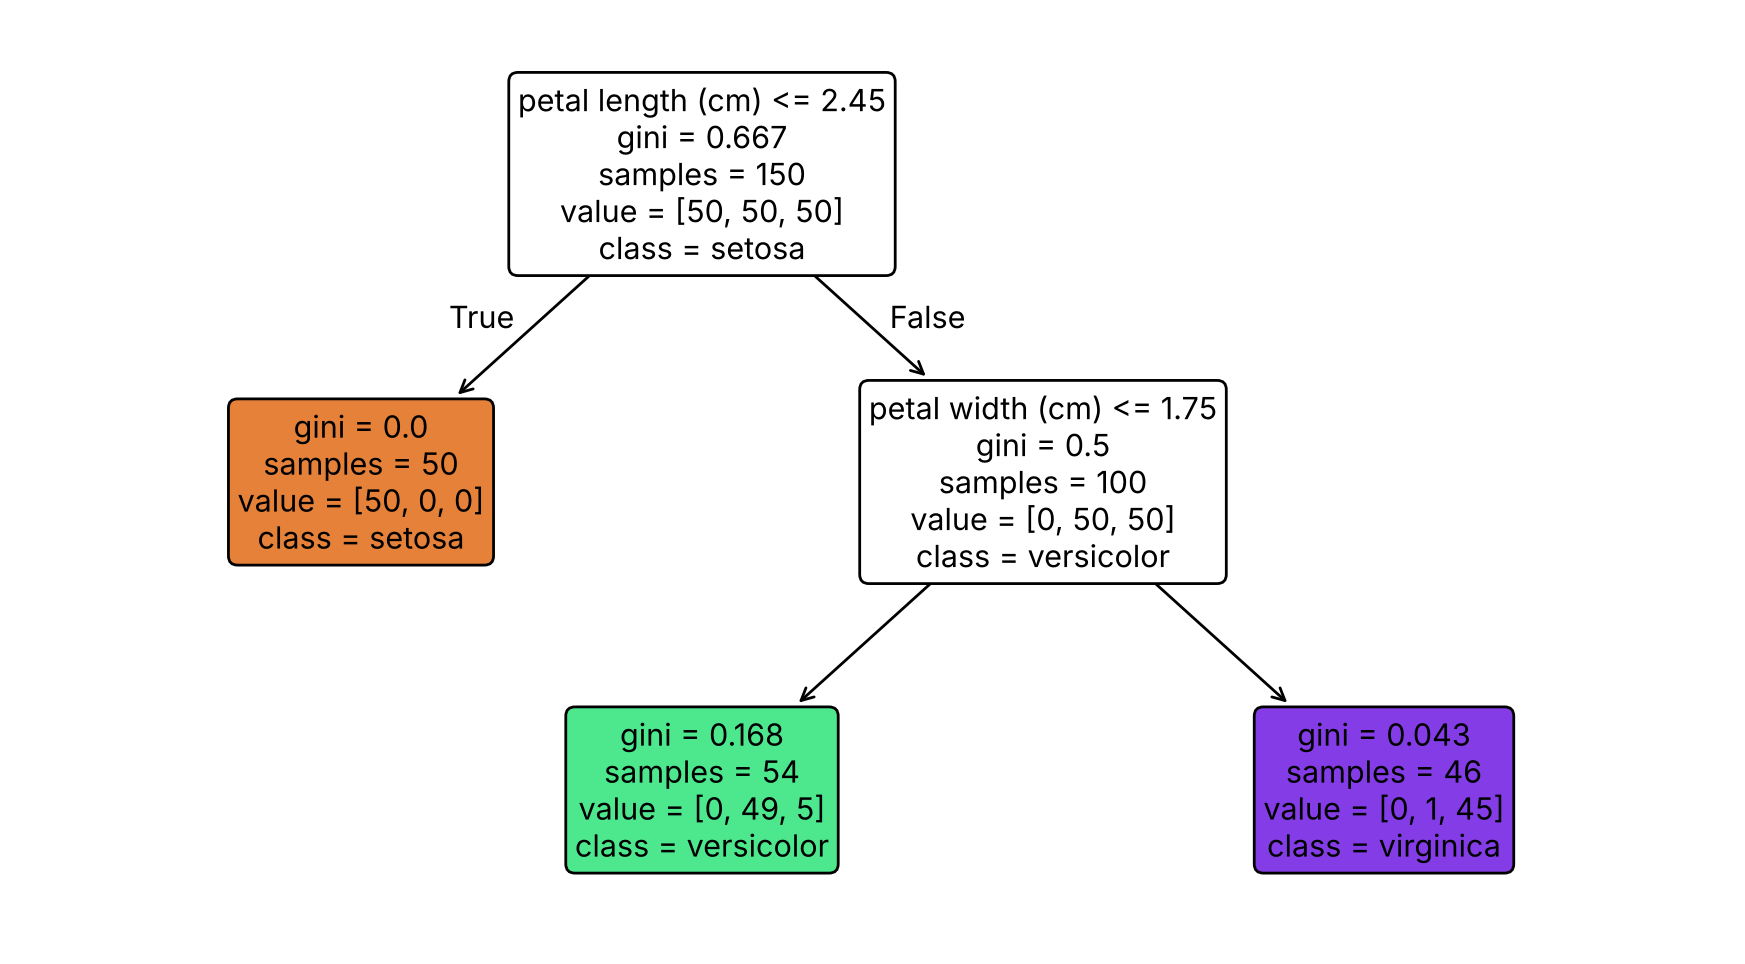

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]]
y = iris.target

tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)

plt.figure(figsize=(11, 6))
plot_tree(tree, feature_names=X.columns, class_names=iris.target_names, filled=True, rounded=True, fontsize=11)
plt.show()

<div dir="rtl">

هر گره نشان می‌دهد:
- سؤال تقسیم (مثلاً `petal length <= 2.45`)
- مقدار **Gini** (ناخالصی گره)
- `samples`: تعداد نمونه‌هایی که به این گره رسیده‌اند
- `value`: تعداد نمونه‌های هر کلاس
- `class`: کلاس اکثریت؛ همان پیش‌بینی اگر این گره برگ باشد

همین درخت را می‌توان به‌صورت قانون‌های متنی هم دید:

</div>

In [2]:
print(export_text(tree, feature_names=list(X.columns)))

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- class: 1
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2



<div dir="rtl">

## ۲. درخت چطور سؤال‌ها را انتخاب می‌کند؟ ناخالصی

در هر گره، درخت **همه‌ی ویژگی‌ها و همه‌ی آستانه‌های ممکن** را امتحان می‌کند و تقسیمی را انتخاب می‌کند که فرزندها تا حد ممکن **خالص** باشند، یعنی بیشتر نمونه‌های هر فرزند از یک کلاس باشند. دو معیار رایج برای ناخالصی گره‌ای با نسبت کلاس‌های $p_k$:

</div>

$$\text{Gini} = 1 - \sum_{k=1}^{K} p_k^2 \qquad \text{Entropy} = -\sum_{k=1}^{K} p_k \log_2 p_k$$

<div dir="rtl">

هر دو معیار برای گره‌ی کاملاً خالص صفر و برای گره‌ای با کلاس‌های مساوی بیشینه‌اند:

</div>

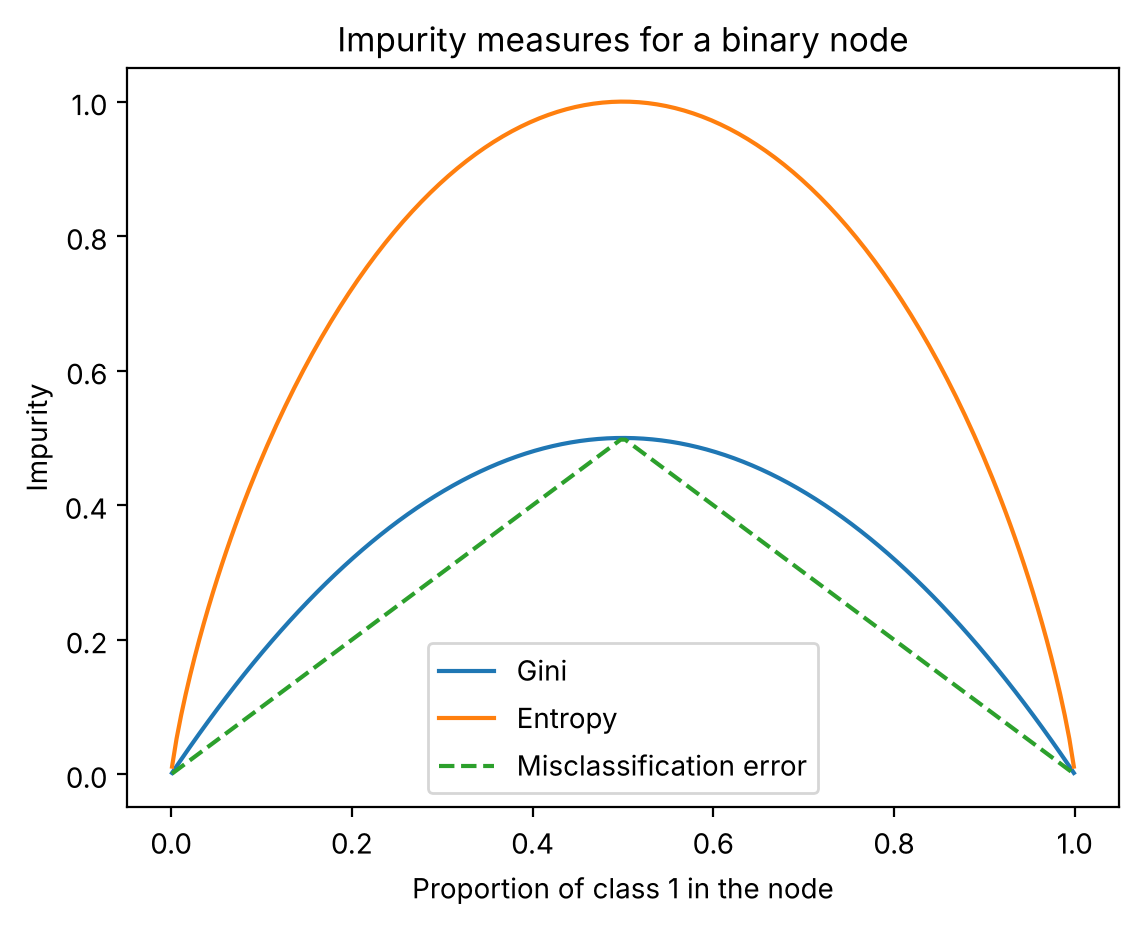

In [3]:
p = np.linspace(0.001, 0.999, 200)
gini = 1 - p ** 2 - (1 - p) ** 2
entropy = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
misclass = 1 - np.maximum(p, 1 - p)

plt.plot(p, gini, label="Gini")
plt.plot(p, entropy, label="Entropy")
plt.plot(p, misclass, label="Misclassification error", linestyle="--")
plt.xlabel("Proportion of class 1 in the node")
plt.ylabel("Impurity")
plt.title("Impurity measures for a binary node")
plt.legend()
plt.show()

<div dir="rtl">

### محاسبه‌ی دستی

ریشه‌ی درخت بالا را حساب کنیم. ۱۵۰ نمونه با سه کلاس ۵۰تایی داریم:

</div>

In [4]:
def gini_impurity(counts):
    counts = np.asarray(counts, dtype=float)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

root = [50, 50, 50]
left = [50, 0, 0]       # petal length <= 2.45
right = [0, 50, 50]

g_root, g_left, g_right = gini_impurity(root), gini_impurity(left), gini_impurity(right)
weighted_children = (sum(left) * g_left + sum(right) * g_right) / sum(root)

print(f"Gini(root)  = {g_root:.3f}")
print(f"Gini(left)  = {g_left:.3f}")
print(f"Gini(right) = {g_right:.3f}")
print(f"Weighted Gini after split = {weighted_children:.3f}")
print(f"Impurity decrease (gain)  = {g_root - weighted_children:.3f}")

Gini(root)  = 0.667
Gini(left)  = 0.000
Gini(right) = 0.500
Weighted Gini after split = 0.333
Impurity decrease (gain)  = 0.333


<div dir="rtl">

درخت از بین همه‌ی تقسیم‌های ممکن، تقسیمی را برمی‌گزیند که بیشترین **کاهش ناخالصی** (بهره) را بدهد. وقتی از آنتروپی استفاده شود، این کاهش را **بهره‌ی اطلاعاتی (Information Gain)** می‌نامند.

### الگوریتم CART

scikit-learn از الگوریتم **CART** استفاده می‌کند:
1. در گره‌ی فعلی، بهترین تقسیم دودویی (ویژگی و آستانه) را پیدا کن.
2. داده را به دو فرزند تقسیم کن.
3. همین کار را برای هر فرزند به‌صورت بازگشتی تکرار کن تا یکی از شرط‌های توقف برقرار شود: گره خالص شود، به حداکثر عمق برسیم، یا تعداد نمونه‌ها کمتر از حد مشخص شود.

این الگوریتم **حریصانه (greedy)** است: در هر مرحله بهترین تقسیم همان لحظه را انتخاب می‌کند و تضمینی نیست که کل درخت بهینه باشد.

## ۳. مرز تصمیم درخت

چون هر سؤال فقط یک ویژگی را با یک آستانه مقایسه می‌کند، مرز تصمیم درخت از خطوط **موازی محورها** تشکیل می‌شود؛ یعنی ناحیه‌هایی مستطیلی.

</div>

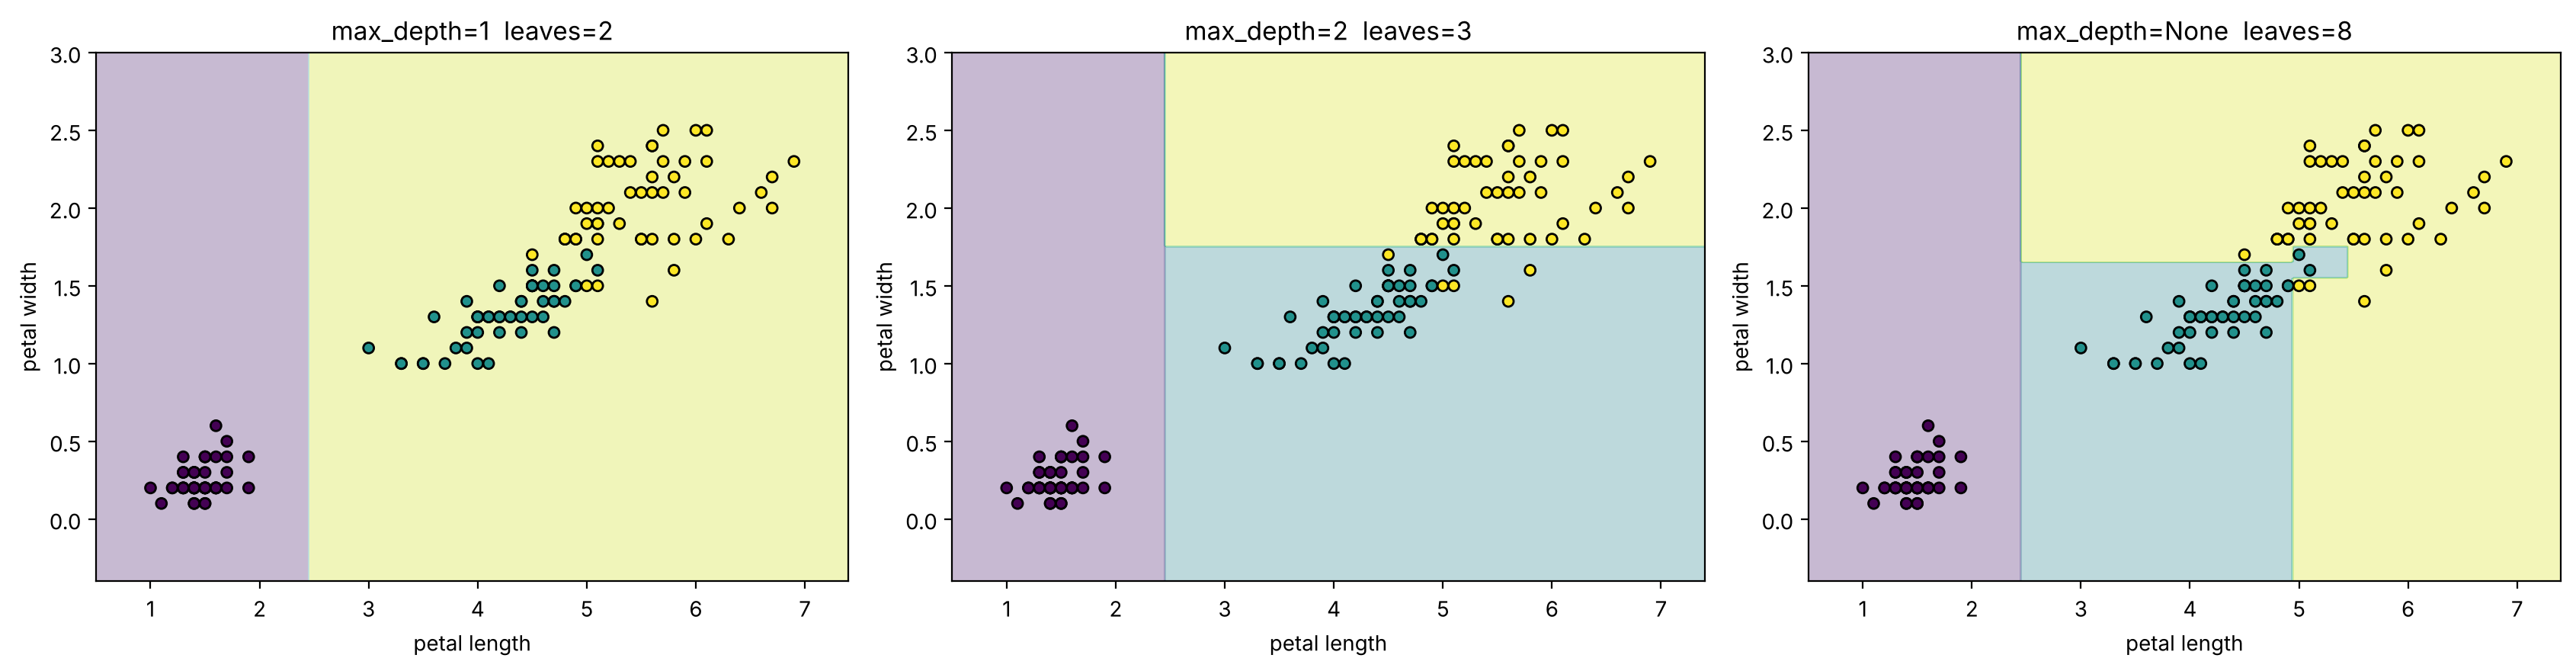

In [5]:
def plot_tree_boundary(model, X, y, ax, title):
    X = np.asarray(X)
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", edgecolor="k", s=25)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, depth in zip(axes, [1, 2, None]):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X.values, y)
    plot_tree_boundary(model, X, y, ax, f"max_depth={depth}  leaves={model.get_n_leaves()}")
    ax.set_xlabel("petal length")
    ax.set_ylabel("petal width")
plt.tight_layout()
plt.show()

<div dir="rtl">

درخت بدون محدودیت عمق (`max_depth=None`) آن‌قدر رشد می‌کند تا همه‌ی برگ‌ها خالص شوند و برای چند نقطه‌ی هم‌پوشان، ناحیه‌های کوچک و عجیبی می‌سازد. این نشانه‌ی **بیش‌برازش** است.

## ۴. بیش‌برازش و کنترل آن

درخت تصمیم بدون محدودیت تقریباً همیشه بیش‌برازش می‌کند، چون می‌تواند برای هر نمونه یک برگ بسازد. ابرپارامترهای اصلی برای کنترل آن (**پیش‌هرس یا Pre-pruning**):

| ابرپارامتر | معنا |
|---|---|
| `max_depth` | حداکثر عمق درخت |
| `min_samples_split` | حداقل نمونه برای تقسیم یک گره |
| `min_samples_leaf` | حداقل نمونه در هر برگ |
| `max_leaf_nodes` | حداکثر تعداد برگ‌ها |
| `max_features` | تعداد ویژگی‌های بررسی‌شده در هر تقسیم |

روی داده‌ی سرطان سینه اثر عمق را ببینیم:

</div>

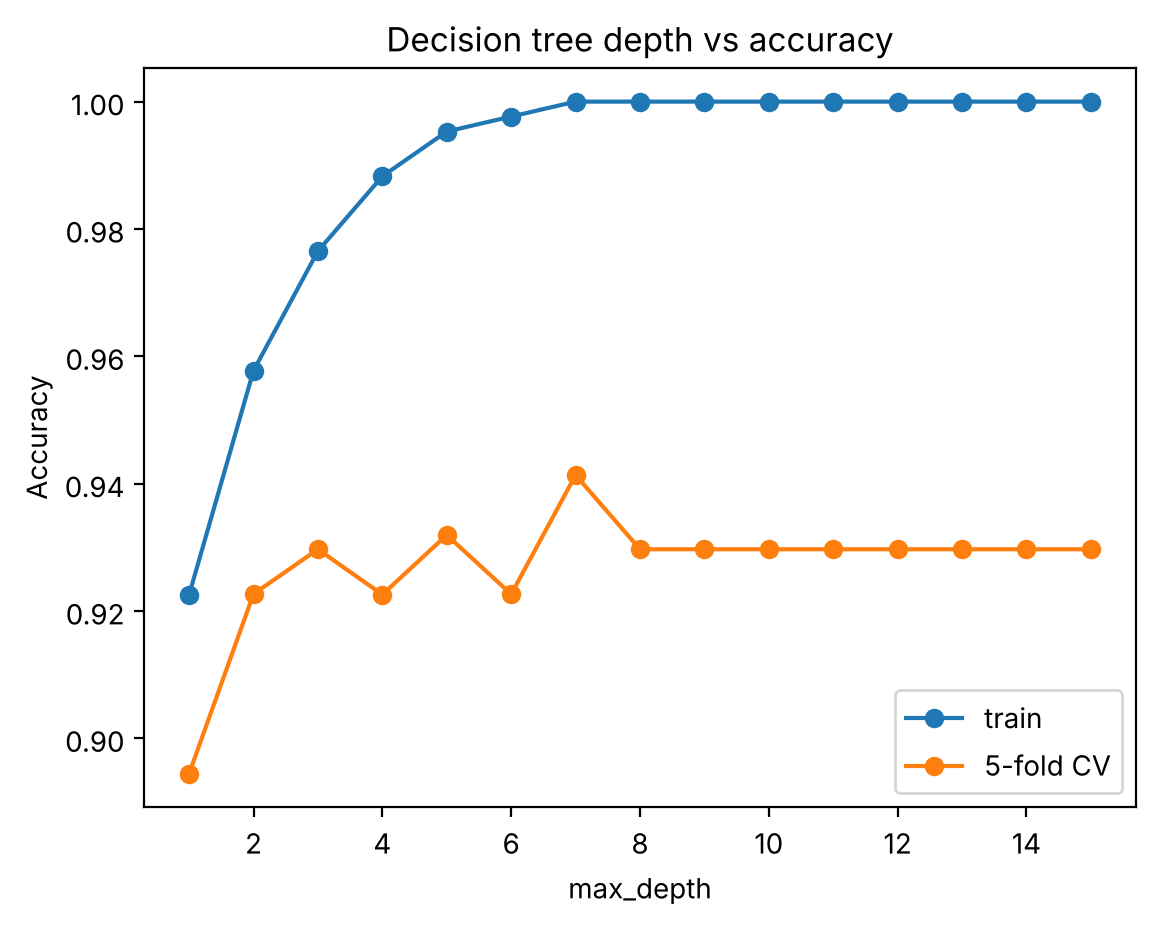

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score

cancer = load_breast_cancer(as_frame=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.25, stratify=cancer.target, random_state=42)

depths = range(1, 16)
train_acc, cv_acc = [], []
for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    train_acc.append(model.fit(Xc_train, yc_train).score(Xc_train, yc_train))
    cv_acc.append(cross_val_score(model, Xc_train, yc_train, cv=5).mean())

plt.plot(depths, train_acc, "o-", label="train")
plt.plot(depths, cv_acc, "o-", label="5-fold CV")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision tree depth vs accuracy")
plt.legend()
plt.show()

<div dir="rtl">

از یک عمق به بعد، دقت آموزش به ۱۰۰٪ می‌رسد ولی دقت اعتبارسنجی بهتر نمی‌شود و حتی کمی افت می‌کند.

### هرس با پیچیدگی-هزینه (Cost-Complexity Pruning)

روش دیگر **پس‌هرس (Post-pruning)** است: اول درخت کامل را می‌سازیم و بعد شاخه‌هایی را که سهم کمی در کاهش خطا دارند حذف می‌کنیم. scikit-learn این کار را با پارامتر `ccp_alpha` انجام می‌دهد: هرچه بزرگ‌تر، درخت کوچک‌تر.

</div>

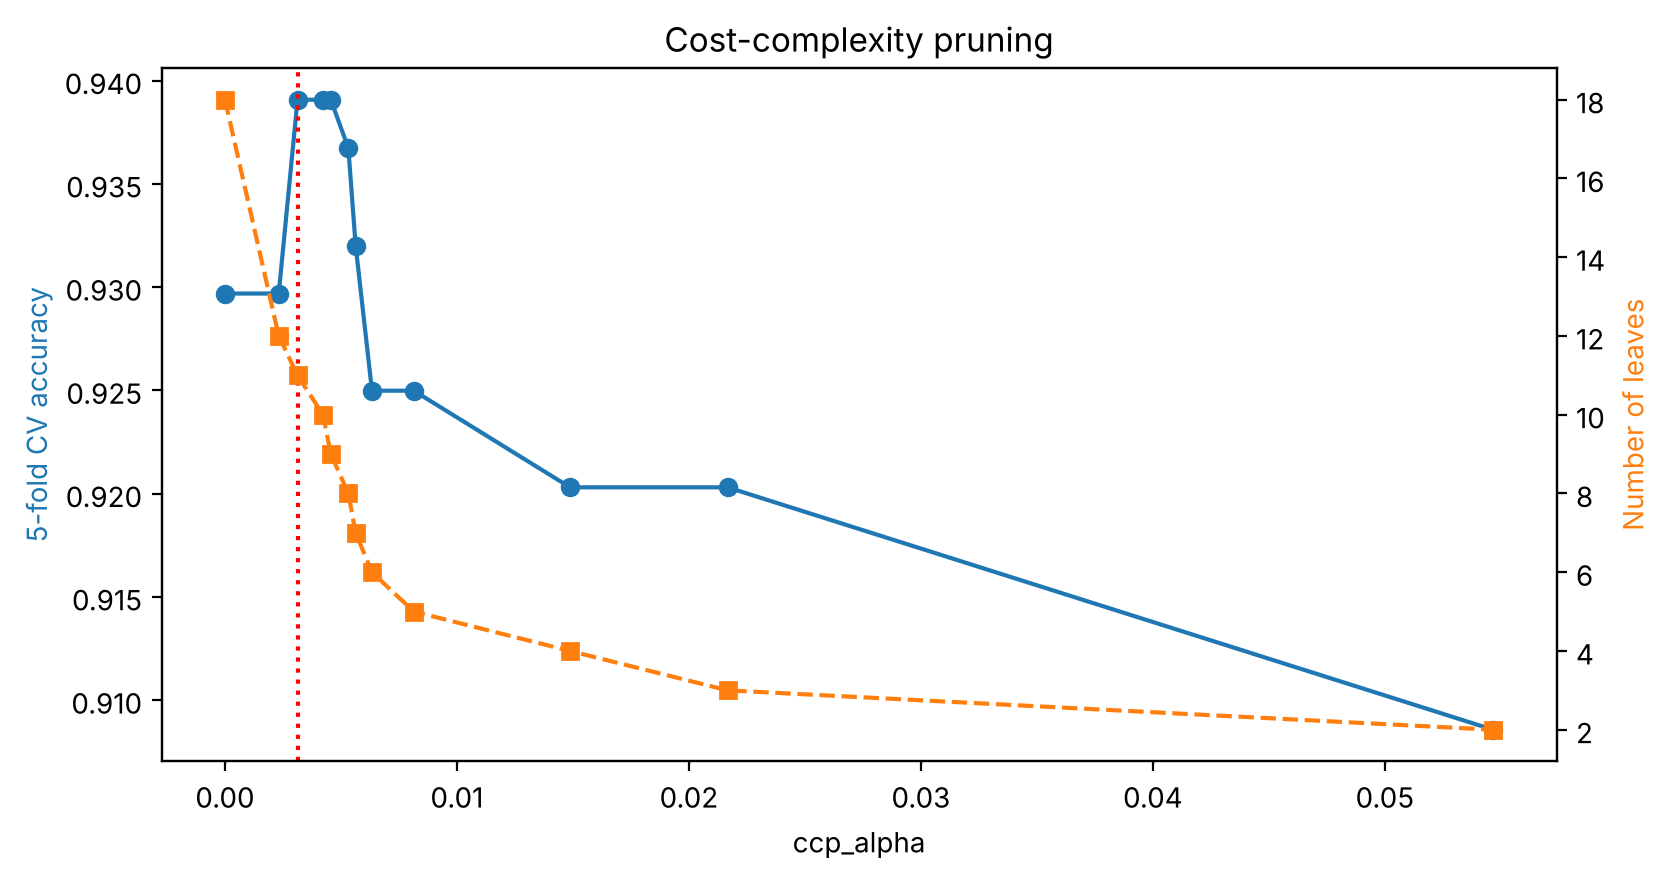

In [7]:
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(Xc_train, yc_train)
alphas = path.ccp_alphas[:-1]       # the last alpha prunes everything down to the root

scores = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=42), Xc_train, yc_train, cv=5).mean()
          for a in alphas]
leaves = [DecisionTreeClassifier(ccp_alpha=a, random_state=42).fit(Xc_train, yc_train).get_n_leaves() for a in alphas]
best_alpha = alphas[int(np.argmax(scores))]

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(alphas, scores, "o-", color="tab:blue")
ax1.set_xlabel("ccp_alpha")
ax1.set_ylabel("5-fold CV accuracy", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(alphas, leaves, "s--", color="tab:orange")
ax2.set_ylabel("Number of leaves", color="tab:orange")
ax1.axvline(best_alpha, color="red", linestyle=":")
plt.title("Cost-complexity pruning")
plt.show()

In [8]:
full_tree = DecisionTreeClassifier(random_state=42).fit(Xc_train, yc_train)
pruned_tree = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42).fit(Xc_train, yc_train)

pd.DataFrame({
    "leaves": [full_tree.get_n_leaves(), pruned_tree.get_n_leaves()],
    "depth": [full_tree.get_depth(), pruned_tree.get_depth()],
    "train accuracy": [full_tree.score(Xc_train, yc_train), pruned_tree.score(Xc_train, yc_train)],
    "test accuracy": [full_tree.score(Xc_test, yc_test), pruned_tree.score(Xc_test, yc_test)],
}, index=["full tree", "pruned tree"]).round(3)

,leaves,depth,train accuracy,test accuracy
full tree,18,7,1.000,0.923
pruned tree,11,5,0.991,0.937


<div dir="rtl">

درخت هرس‌شده کوچک‌تر و ساده‌تر است (برگ‌ها و عمق کمتر) و با وجود دقت آموزش کمتر، دقت آزمونش کمی بهتر از درخت کامل است. درخت کوچک‌تر، تفسیرپذیرتر هم هست:

</div>

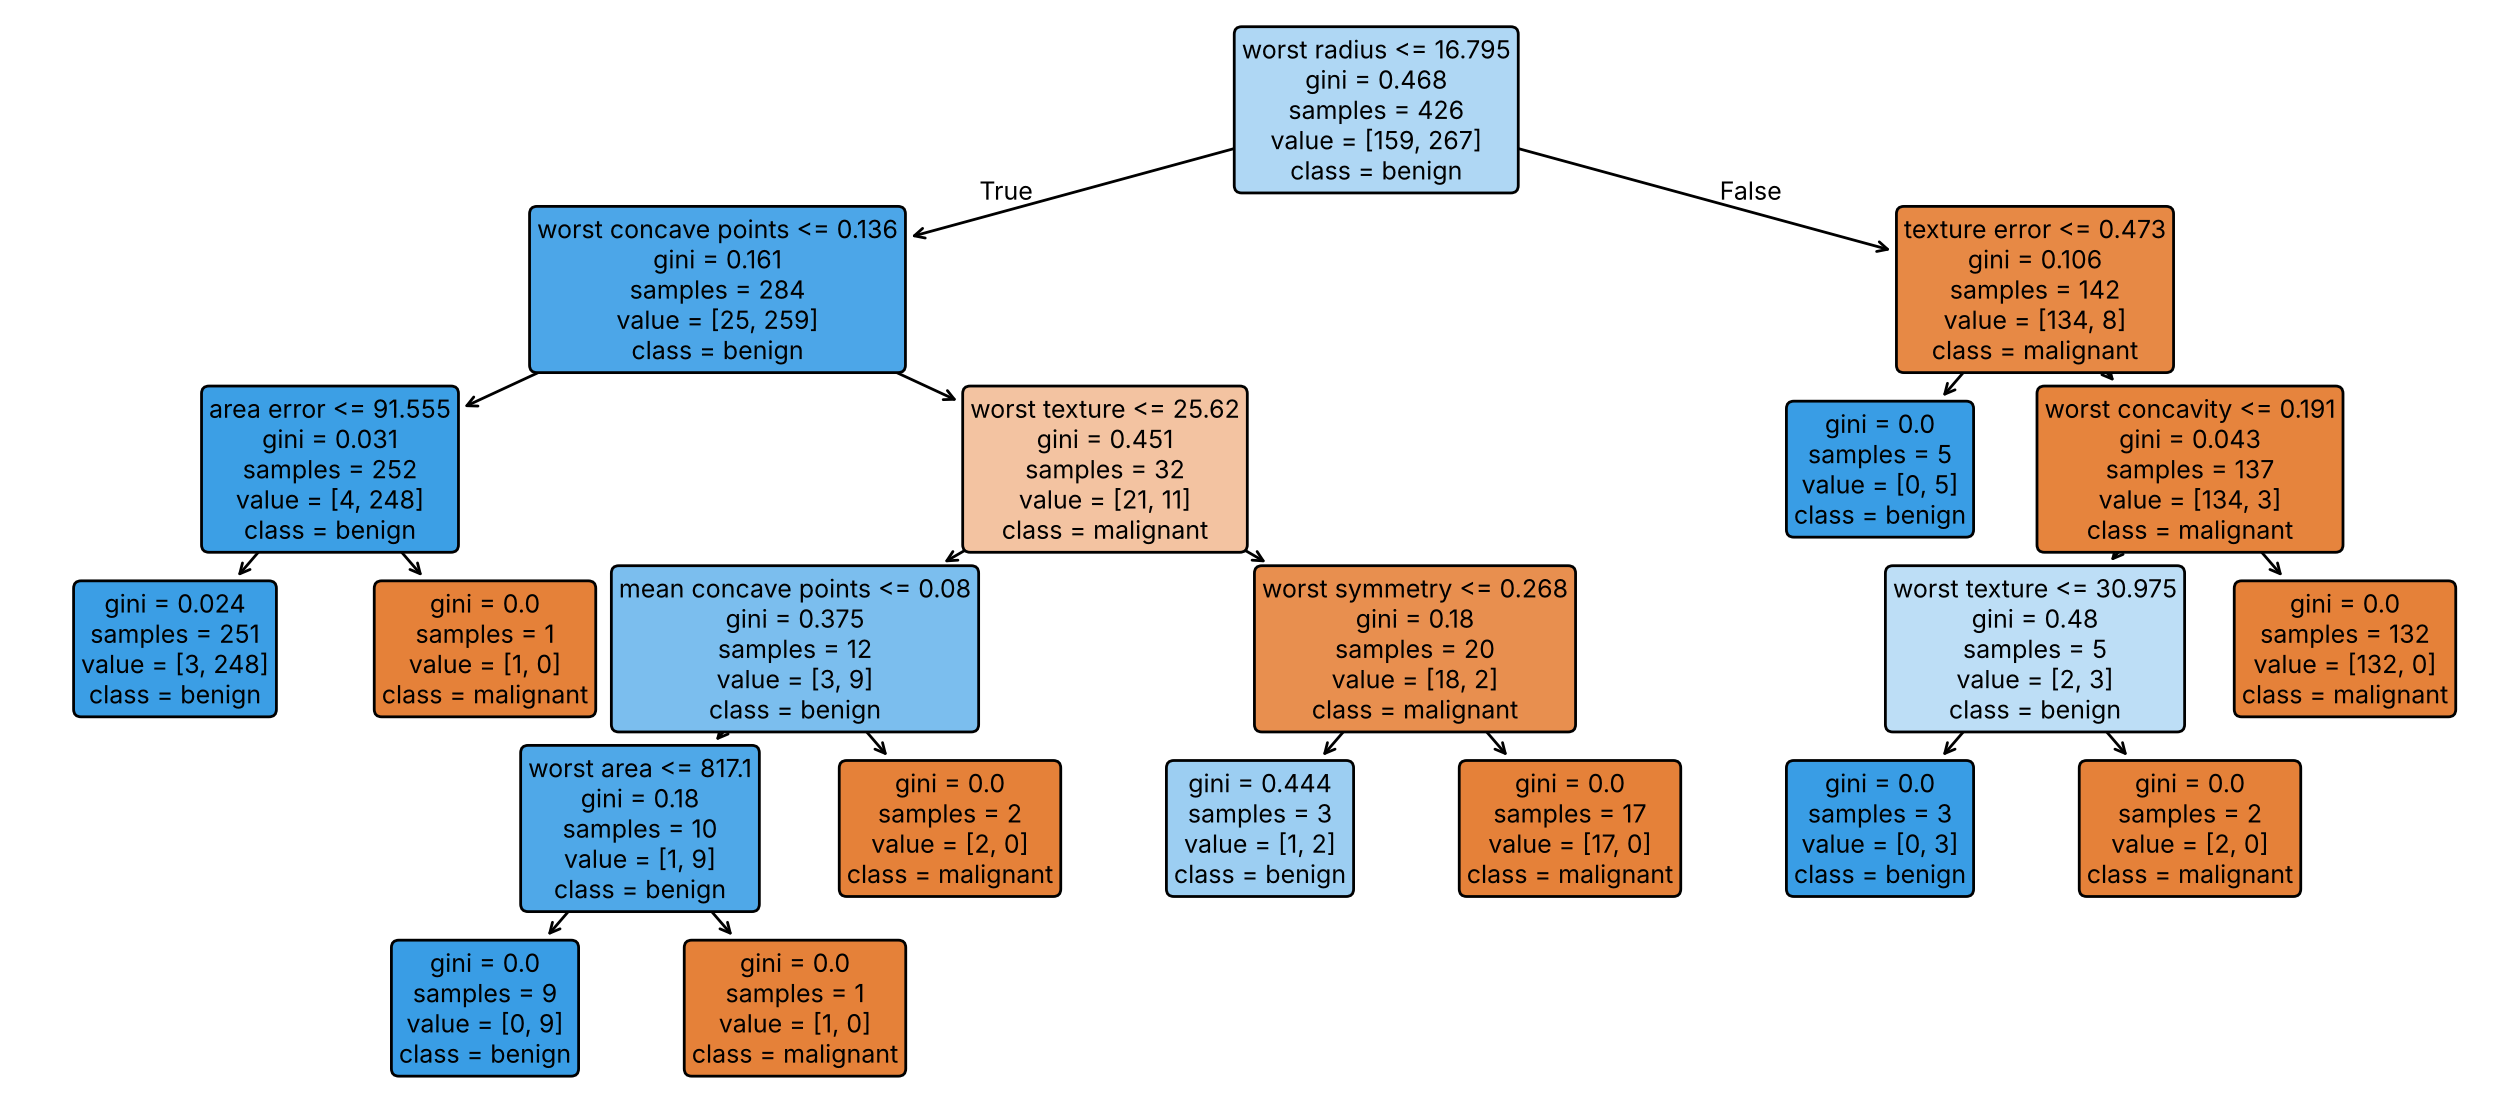

In [9]:
plt.figure(figsize=(16, 7))
plot_tree(pruned_tree, feature_names=cancer.feature_names, class_names=cancer.target_names,
          filled=True, rounded=True, fontsize=9)
plt.show()

<div dir="rtl">

## ۵. اهمیت ویژگی‌ها

درخت برای هر ویژگی محاسبه می‌کند که در مجموع همه‌ی گره‌هایی که از آن استفاده شده، چقدر ناخالصی را کاهش داده است. این عدد **اهمیت ویژگی (Feature Importance)** است.

</div>

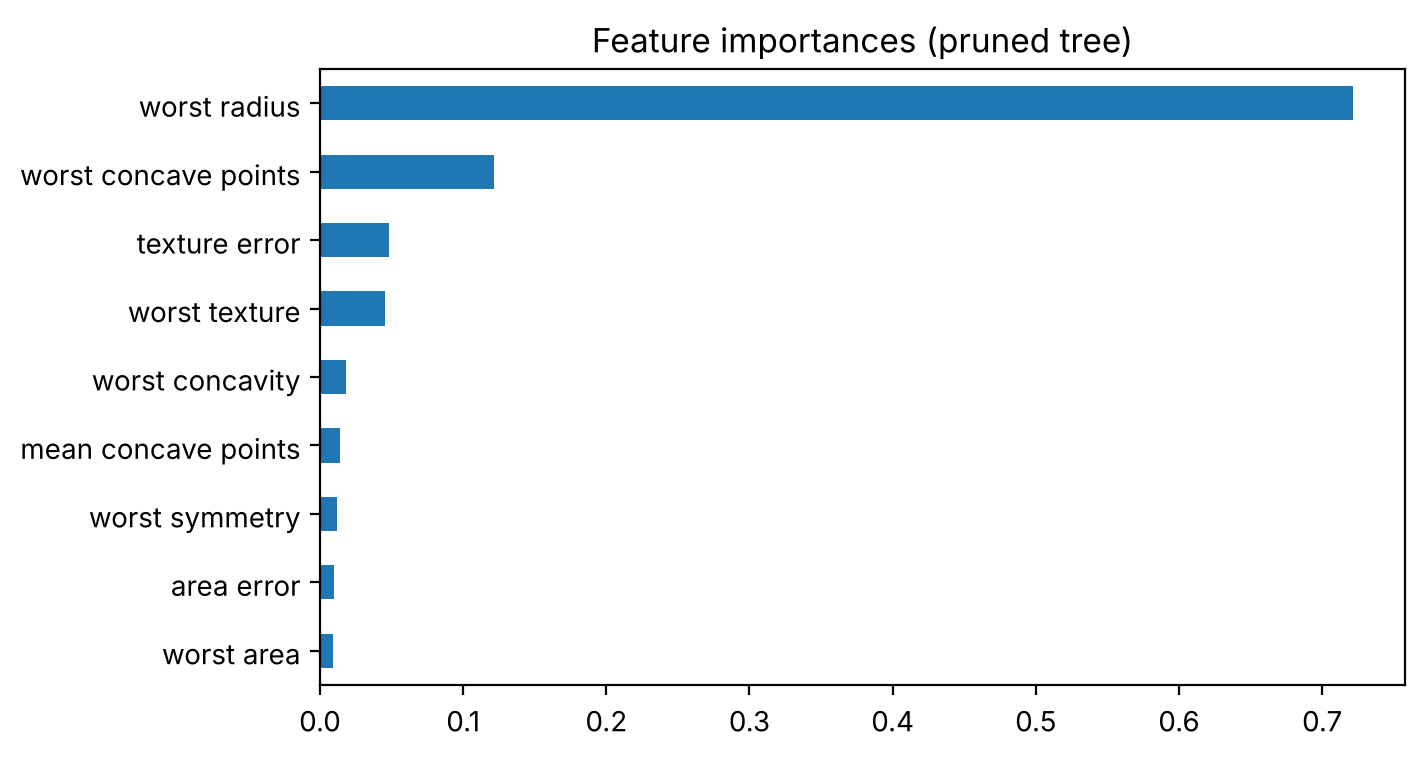

In [10]:
importances = pd.Series(pruned_tree.feature_importances_, index=cancer.feature_names)
importances[importances > 0].sort_values().plot.barh(figsize=(7, 4))
plt.title("Feature importances (pruned tree)")
plt.show()

<div dir="rtl">

**هشدار:** این روش اهمیت را برای ویژگی‌های عددی با مقادیر یکتای زیاد بیش از حد برآورد می‌کند. در جلسه‌ی ۹ روش قابل اعتمادتری به نام **Permutation Importance** را می‌بینیم.

## ۶. درخت رگرسیون

درخت تصمیم برای رگرسیون هم کار می‌کند. تفاوت‌ها:
- به‌جای ناخالصی، **MSE** هر گره کمینه می‌شود.
- پیش‌بینی هر برگ، **میانگین** هدف نمونه‌های آن برگ است.
- در نتیجه، تابع پیش‌بینی به شکل **پله‌ای** است.

</div>

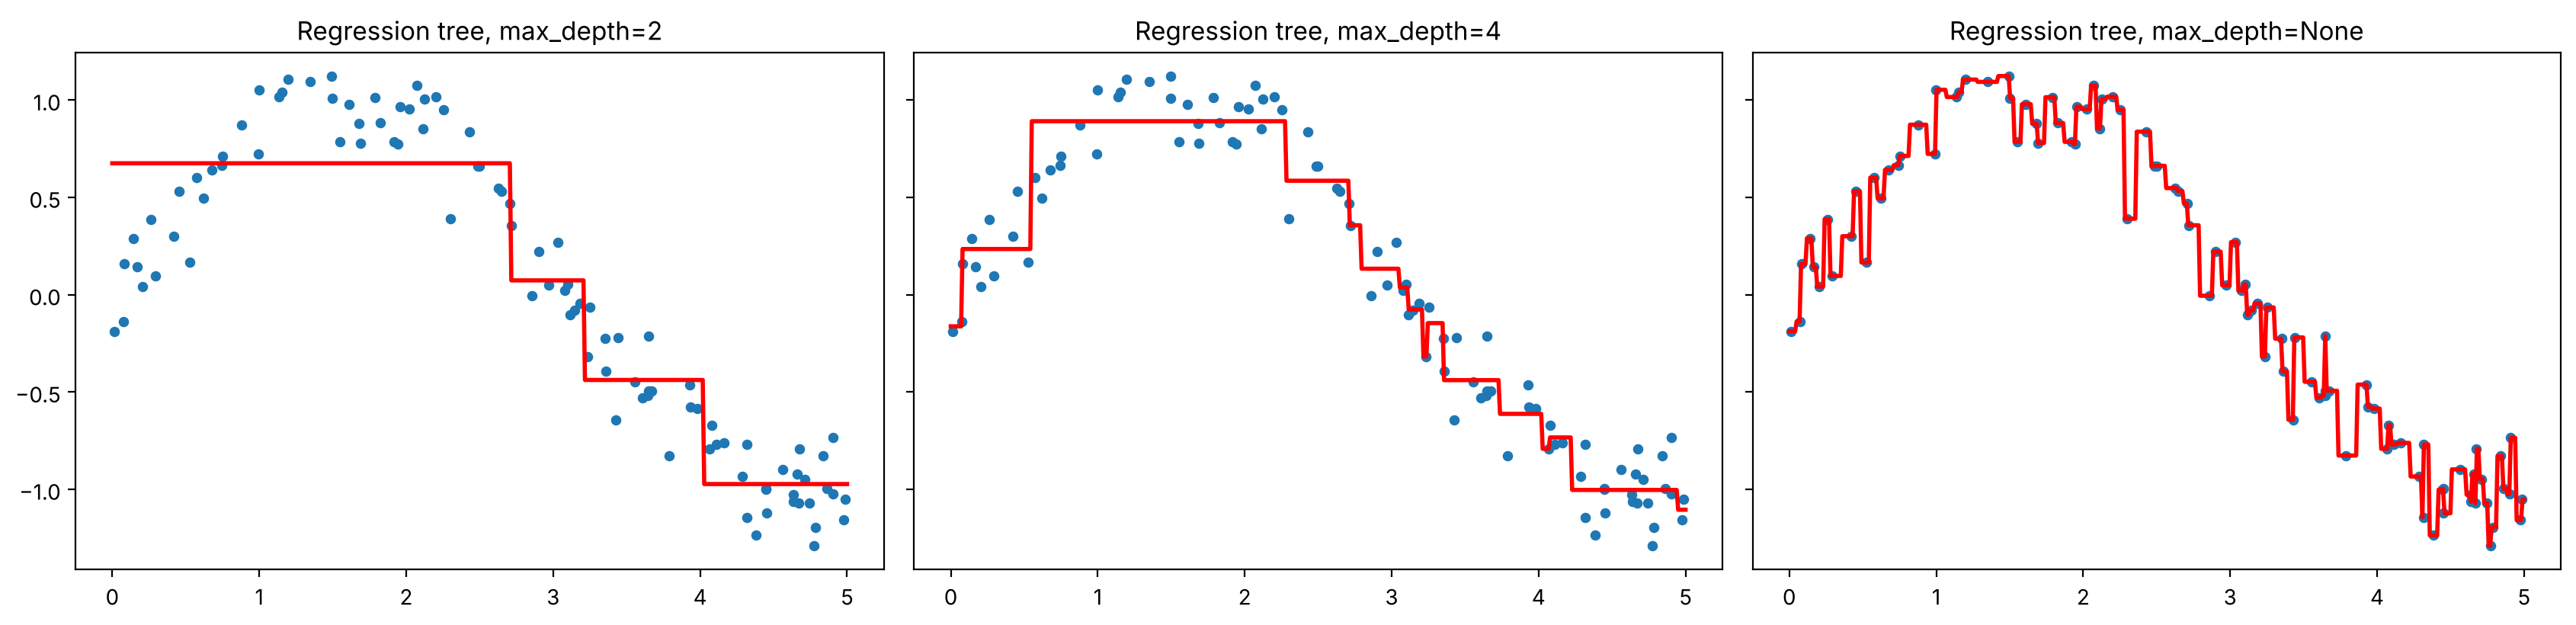

In [11]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(0)
X_r = np.sort(5 * rng.random((100, 1)), axis=0)
y_r = np.sin(X_r).ravel() + rng.normal(0, 0.15, 100)
x_plot = np.linspace(0, 5, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, depth in zip(axes, [2, 4, None]):
    reg = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_r, y_r)
    ax.scatter(X_r, y_r, s=15)
    ax.plot(x_plot, reg.predict(x_plot), color="red", linewidth=2)
    ax.set_title(f"Regression tree, max_depth={depth}")
plt.tight_layout()
plt.show()

<div dir="rtl">

درخت رگرسیون نمی‌تواند خارج از بازه‌ی داده‌ی آموزش **برون‌یابی (extrapolation)** کند؛ برای هر ورودی بیرون از این بازه، مقدار نزدیک‌ترین برگ را برمی‌گرداند.

## ۷. ناپایداری درخت‌ها

بزرگ‌ترین ضعف درخت‌ها **واریانس زیاد** است: تغییر کوچک در داده‌ی آموزش می‌تواند درخت کاملاً متفاوتی بسازد. دو درخت را روی دو نمونه‌ی تصادفی ۹۰ درصدی از همان داده آموزش می‌دهیم:

</div>

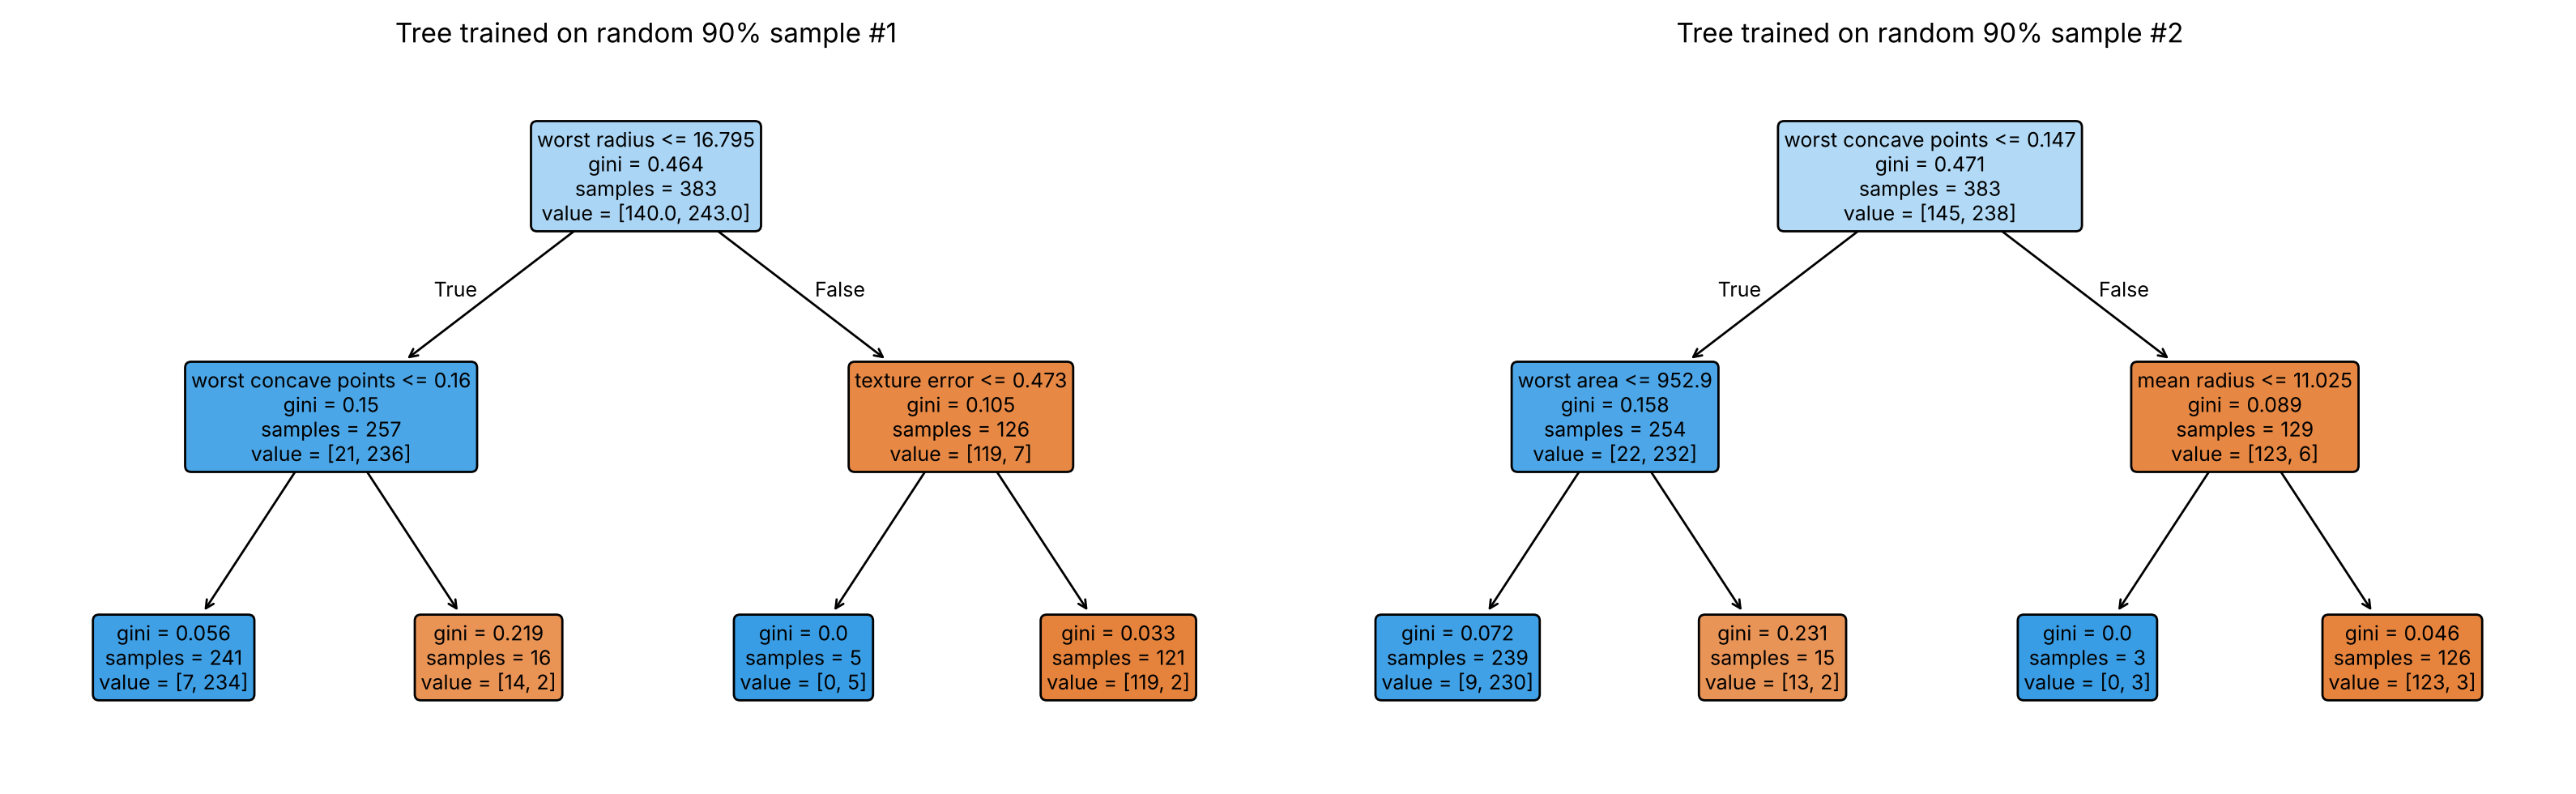

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, seed in zip(axes, [1, 2]):
    idx = np.random.default_rng(seed).choice(len(Xc_train), size=int(0.9 * len(Xc_train)), replace=False)
    t = DecisionTreeClassifier(max_depth=2, random_state=0).fit(Xc_train.iloc[idx], yc_train.iloc[idx])
    plot_tree(t, feature_names=cancer.feature_names, filled=True, rounded=True, fontsize=9, ax=ax)
    ax.set_title(f"Tree trained on random 90% sample #{seed}")
plt.tight_layout()
plt.show()

<div dir="rtl">

با وجود اینکه ۹۰٪ داده‌ها مشترک است، حتی **ریشه‌ی** دو درخت متفاوت است: یکی با `worst radius` شروع می‌کند و دیگری با `worst concave points`، و ویژگی‌های سطح دوم هم فرق دارند. راه حل این ناپایداری، **ترکیب تعداد زیادی درخت** است؛ موضوع جلسه‌ی بعد.

## ۸. جمع‌بندی

| مزایا | معایب |
|---|---|
| بسیار تفسیرپذیر و قابل رسم | بیش‌برازش شدید بدون هرس |
| بدون نیاز به مقیاس‌بندی | ناپایدار (واریانس زیاد) |
| کار با ویژگی‌های عددی و دسته‌ای | مرزهای فقط موازی محورها |
| تشخیص خودکار رابطه‌های غیرخطی و تعامل ویژگی‌ها | ناتوان در برون‌یابی |

- درخت با تقسیم‌های حریصانه، ناخالصی (Gini یا آنتروپی) را کم می‌کند.
- بیش‌برازش را با `max_depth`، `min_samples_leaf` یا هرس با `ccp_alpha` کنترل کنید و مقدار مناسب را با اعتبارسنجی بیابید.
- واریانس زیاد درخت‌ها، انگیزه‌ی اصلی روش‌های گروهی است.

## ۹. تمرین

1. درخت بخش ۱ را با `criterion="entropy"` بسازید. ساختار درخت تغییر می‌کند؟
2. با `GridSearchCV` بهترین ترکیب `max_depth` و `min_samples_leaf` را برای داده‌ی سرطان پیدا کنید و با درخت هرس‌شده مقایسه کنید.
3. یک درخت رگرسیون روی داده‌ی مسکن جلسه‌ی ۳ آموزش دهید. با `max_depth` مختلف، RMSE آزمون را با رگرسیون خطی مقایسه کنید.
4. داده‌ی Titanic جلسه‌ی ۲ را با یک درخت به عمق ۳ مدل کنید و درخت را رسم کنید. قوانین کشف‌شده با یافته‌های EDA هم‌خوانی دارند؟

</div>